### Creating Chatbot with using Multiple Tools Using LangGraph

In [1]:
from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper

/var/folders/12/zt3xcr4d475gzrfc596w39xm0000gn/T/ipykernel_24477/4084895585.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun


In [2]:
api_wrapper_arxiv = ArxivAPIWrapper(top_k_results=2, docs_content_chars_max=500)
arxiv = ArxivQueryRun(api_wrapper=api_wrapper_arxiv,)

print(arxiv.name)

arxiv


In [3]:
arxiv.invoke("Attention is all you need paper summary")

'Published: 2006-01-22\nTitle: This paper has been withdrawn\nAuthors: This paper has been withdrawn\nSummary: This paper has been withdrawn\n\nPublished: 2025-12-03\nTitle: "All You Need" is Not All You Need for a Paper Title: On the Origins of a Scientific Meme\nAuthors: Anton Alyakin\nSummary: The 2017 paper \'\'Attention Is All You Need\'\' introduced the Transformer architecture-and inadvertently spawned one of machine learning\'s most persistent naming conventions. We analyze 717 arXiv preprints containing \'\'All You Need\'\' in their titles (2009-2025), finding exponential growth ($R^2$ > 0.994) following the original paper, with 200 titles in 2025 alone. Among papers following the canonical \'\'X [Is] All You Need\'\' structure, \'\'Attention\'\' remains the most frequently claimed necessity (28 occurrences). Situating this phenomenon within memetic theory, we argue the pattern\'s success reflects competitive pressures in scientific communication that increasingly favor memora

In [32]:
from datetime import timedelta
import wikipedia

# Identify this client and pace requests to avoid Wikipedia API rate limits.
wikipedia.set_user_agent("LangGraph learning notebook/1.0 (https://github.com/ajaypara01/Lang-Graph)")
wikipedia.set_rate_limiting(True, min_wait=timedelta(seconds=1))

api_wrapper_wikipedia = WikipediaAPIWrapper(top_k_results=3, docs_content_chars_max=1000)
wikipedia = WikipediaQueryRun(api_wrapper=api_wrapper_wikipedia,)
wikipedia.invoke("What is LangGraph?")

JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [6]:
from langchain_community.tools.tavily_search import TavilySearchResults
tavily = TavilySearchResults()

/var/folders/12/zt3xcr4d475gzrfc596w39xm0000gn/T/ipykernel_24477/1535493036.py:2: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily = TavilySearchResults()


In [7]:
tavily.invoke("What is Python recent version today nov 2026?")

[{'title': 'Python 3.15 Ships and Other Python News for November 2026 – Real Python',
  'url': 'https://realpython.com/python-news-november-2026',
  'content': 'Only 3.15.2 and 3.14.10 come with binary installers, while the older branches are source-only security releases. The October 26 batch also fixes a `tarfile` extraction filter bypass that could write files outside the destination directory, so it’s worth installing even if certificates aren’t keeping you up at night.\n\nPatching takes three separate steps, because the interpreter, the packages in each environment, and `uv` all carry their own copy of the fix.\n\nFirst, upgrade Python itself with the tool you used to install it, such as the python.org installer, your system package manager, or `uv python install`. Then check the version:\n\nLanguage: Shell\n\n```\n $  Python 3.14.10\n``` [...] Language: Shell\n\n```\n $  Python 3.14.10\n```\n\nYou’re looking for 3.15.2, 3.14.10, 3.13.18, 3.12.16, or 3.11.18, depending on your bra

In [33]:
tools = [arxiv, tavily]

In [34]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model_name="gpt-4o-mini")
llm_with_tools = llm.bind_tools(tools)

In [35]:
from langchain_core.messages import HumanMessage, AIMessage
llm_with_tools.invoke([HumanMessage(content="What is the capital of France?")])

AIMessage(content='The capital of France is Paris.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 159, 'total_tokens': 167, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_52db65ba89', 'id': 'chatcmpl-EjoMWYZrwIXvklhORGPXBdRcLKgVR', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1d5b9-62c5-711f-8fc5-3dc1f5d9043f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 159, 'output_tokens': 8, 'total_tokens': 167, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [36]:
from typing_extensions import TypedDict
from typing import Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages
# STate Schema
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

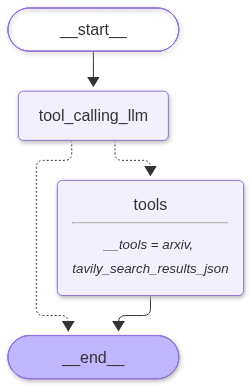

In [37]:
from langgraph.graph import StateGraph, START, END
from IPython.display import display, Image
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

# Node Definition
def tool_calling_llm(state: State):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}



graph_builder = StateGraph(State)
graph_builder.add_node("tool_calling_llm", tool_calling_llm)
graph_builder.add_node("tools", ToolNode(tools))

graph_builder.add_edge(START, "tool_calling_llm")
graph_builder.add_conditional_edges("tool_calling_llm", tools_condition)
graph_builder.add_edge("tools", END)

graph = graph_builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [38]:
messages = graph.invoke({
    "messages": [HumanMessage(content="What is the capital of France?")]
})
for message in messages["messages"]:
    message.pretty_print()

================================ Human Message =================================

What is the capital of France?
================================== Ai Message ==================================

The capital of France is Paris.
